Sel 1: muat data dan siapkan label

In [1]:
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

from review_nlp.ingestion.transform import refilter
from review_nlp.preprocessing import preprocess
from review_nlp.sentiment.evaluate import evaluate
from review_nlp.sentiment.labels import LABELS_3, rating_to_label
from review_nlp.sentiment.tfidf_lr import TfidfLrClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/raw/com.whatsapp_2026-08-19_2026-11-17.parquet")
df = refilter(df)
df["reviewed_at"] = pd.to_datetime(df["reviewed_at"])

used = df[df["exclude_reason"].isna()].copy()
used["label"] = used["rating"].map(rating_to_label)
used["clean"] = used["text_raw"].map(preprocess)
used = used[used["clean"].str.len() > 0]
print("Data dipakai:", len(used))
used["label"].value_counts(normalize=True).round(3)

Data dipakai: 5846


label
positif    0.512
negatif    0.399
netral     0.089
Name: proportion, dtype: float64

Sel 2: skenario A, split acak (3 kelas)

In [2]:
train, test = train_test_split(used, test_size=0.2, stratify=used["label"], random_state=42)
clf = TfidfLrClassifier().fit(train["clean"], train["label"])
test = test.assign(pred=[r.label for r in clf.predict(test["clean"].tolist())])
res_a = evaluate(test["label"], test["pred"], LABELS_3)
print("Latih:", len(train), "| uji:", len(test))
print("Macro-F1 skenario A:", round(res_a["macro_f1"], 4))
print(res_a["report"])

Latih: 4676 | uji: 1170
Macro-F1 skenario A: 0.5723
              precision    recall  f1-score   support

     negatif       0.69      0.72      0.70       467
      netral       0.21      0.38      0.27       104
     positif       0.82      0.68      0.75       599

    accuracy                           0.67      1170
   macro avg       0.57      0.59      0.57      1170
weighted avg       0.72      0.67      0.69      1170



Sel 3: confusion matrix

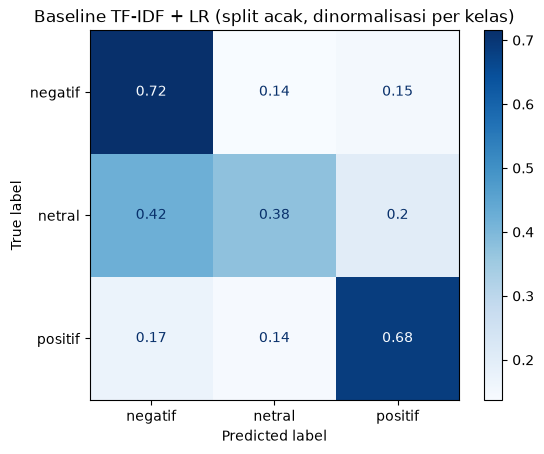

In [3]:
ConfusionMatrixDisplay.from_predictions(
    test["label"], test["pred"], labels=LABELS_3, normalize="true", cmap="Blues"
)
plt.title("Baseline TF-IDF + LR (split acak, dinormalisasi per kelas)")
plt.savefig(ROOT / "docs/images/baseline_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

Sel 4: skenario B, split waktu (3 minggu terakhir untuk uji)

In [4]:
cutoff = used["week_index"].max() - 2
train_t = used[used["week_index"] <= cutoff]
test_t = used[used["week_index"] > cutoff]
clf_t = TfidfLrClassifier().fit(train_t["clean"], train_t["label"])
pred_t = [r.label for r in clf_t.predict(test_t["clean"].tolist())]
res_b = evaluate(test_t["label"], pred_t, LABELS_3)
print("Latih:", len(train_t), "| uji:", len(test_t))
print(
    "Proporsi negatif: latih", round((train_t["label"] == "negatif").mean(), 3),
    "| uji", round((test_t["label"] == "negatif").mean(), 3),
)
print("Macro-F1 skenario B:", round(res_b["macro_f1"], 4))
print(res_b["report"])

Latih: 4975 | uji: 871
Proporsi negatif: latih 0.412 | uji 0.327
Macro-F1 skenario B: 0.5114
              precision    recall  f1-score   support

     negatif       0.57      0.60      0.58       285
      netral       0.16      0.26      0.19        89
     positif       0.82      0.70      0.76       497

    accuracy                           0.62       871
   macro avg       0.52      0.52      0.51       871
weighted avg       0.67      0.62      0.64       871



Sel 5: sensitivitas terhadap 9 September

In [5]:
H = pd.Timestamp("2026-09-09").date()
mask_tr = train["reviewed_at"].dt.date != H
clf_s = TfidfLrClassifier().fit(train.loc[mask_tr, "clean"], train.loc[mask_tr, "label"])
test_s = test[test["reviewed_at"].dt.date != H]
pred_full = [r.label for r in clf.predict(test_s["clean"].tolist())]
pred_s = [r.label for r in clf_s.predict(test_s["clean"].tolist())]
f1_full = evaluate(test_s["label"], pred_full, LABELS_3)["macro_f1"]
f1_s = evaluate(test_s["label"], pred_s, LABELS_3)["macro_f1"]
print("Data latih dibuang:", int((~mask_tr).sum()), "| uji (tanpa 9 Sep):", len(test_s))
print("Macro-F1 model penuh       :", round(f1_full, 4))
print("Macro-F1 latih tanpa 9 Sep :", round(f1_s, 4))

Data latih dibuang: 138 | uji (tanpa 9 Sep): 1138
Macro-F1 model penuh       : 0.5761
Macro-F1 latih tanpa 9 Sep : 0.5712


Sel 6: pembanding tebak mayoritas

In [6]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(np.zeros((len(train), 1)), train["label"])
pred_d = dummy.predict(np.zeros((len(test), 1)))
res_d = evaluate(test["label"], pred_d, LABELS_3)
print("Macro-F1 tebak mayoritas:", round(res_d["macro_f1"], 4))

Macro-F1 tebak mayoritas: 0.2257


Sel 7: n-gram paling berpengaruh per kelas

In [7]:
tfidf = clf.pipeline.named_steps["tfidf"]
lr = clf.pipeline.named_steps["lr"]
terms = np.array(tfidf.get_feature_names_out())
for i, kelas in enumerate(lr.classes_):
    top = terms[np.argsort(lr.coef_[i])[-15:][::-1]]
    print(f"{kelas:8s}->", ", ".join(top))

negatif -> jelek, tidak, gajelas, terus, malah, blokir, tolol, akun, jelas, lu, nomor, merugikan, mengecewakan, versi, pakai
netral  -> susah, reset, telat, download whatsapp, mohon, sangat efektif, padahal, dlu, mintak, call tidak, obrolan, ku tidak, dulu, dan mantap, akun aku
positif -> bagus, sangat, knpa, mantap, komunikasi, keren, baguss, biar, berguna, membantu, aman, suka, tambahin, baik, bagus banget


Sel 8: kata yang melonjak di ulasan negatif pada 3 minggu terakhir

In [8]:
def doc_freq(d):
    neg = d[d["label"] == "negatif"]
    c = Counter(t for s in neg["clean"] for t in set(s.split()))
    return {w: v / max(len(neg), 1) for w, v in c.items()}


f_old, f_new = doc_freq(train_t), doc_freq(test_t)
naik = sorted(
    ((w, f_new[w] - f_old.get(w, 0.0)) for w in f_new if f_new[w] > 0.01),
    key=lambda x: -x[1],
)[:15]
pd.DataFrame(naik, columns=["kata", "kenaikan_proporsi"]).round(3)

,kata,kenaikan_proporsi
0,dan,0.057
1,saya,0.047
2,nya,0.045
3,karena,0.040
4,ada,0.036
5,suara,0.029
6,untuk,0.027
7,status,0.026
8,saat,0.023
9,selalu,0.022


Sel 9: skenario C, 2 kelas (tanpa bintang 3)

In [9]:
two = used.copy()
two["label"] = two["rating"].map(lambda r: rating_to_label(r, three_class=False))
two = two.dropna(subset=["label"])
tr, te = train_test_split(two, test_size=0.2, stratify=two["label"], random_state=42)
clf_2 = TfidfLrClassifier().fit(tr["clean"], tr["label"])
pred_2 = [r.label for r in clf_2.predict(te["clean"].tolist())]
res_c = evaluate(te["label"], pred_2, ["negatif", "positif"])
print("Latih:", len(tr), "| uji:", len(te))
print("Macro-F1 skenario C:", round(res_c["macro_f1"], 4))
print(res_c["report"])

Latih: 4260 | uji: 1065
Macro-F1 skenario C: 0.7794
              precision    recall  f1-score   support

     negatif       0.72      0.82      0.77       467
     positif       0.84      0.75      0.79       598

    accuracy                           0.78      1065
   macro avg       0.78      0.78      0.78      1065
weighted avg       0.79      0.78      0.78      1065



Sel 10: tabel ringkasan

In [10]:
ringkasan = pd.DataFrame(
    {
        "skenario": [
            "Tebak mayoritas (3 kelas)",
            "A: acak, 3 kelas",
            "B: waktu, 3 kelas",
            "C: acak, 2 kelas",
        ],
        "macro_f1": [
            res_d["macro_f1"],
            res_a["macro_f1"],
            res_b["macro_f1"],
            res_c["macro_f1"],
        ],
    }
).round(4)
ringkasan

,skenario,macro_f1
0,Tebak mayoritas (3 kelas),0.2257
1,"A: acak, 3 kelas",0.5723
2,"B: waktu, 3 kelas",0.5114
3,"C: acak, 2 kelas",0.7794


Sel 11: contoh salah prediksi (melihat label noisy)

In [11]:
wrong = test[test["label"] != test["pred"]]
wrong[["rating", "pred", "text_raw"]].sample(15, random_state=1)

,rating,pred,text_raw
2098,5,negatif,Tanpa alasan apapun nomor saya memerlukan what...
2810,5,negatif,Kurang baik sinyal nya
6104,1,positif,saya sangat benci melihat whatsapp ini karena ...
9000,1,positif,"Maunya aplikasi WhatsApp, jangan ditimbulkan l..."
2486,5,negatif,"saluran nya di perketatlah, masa isinya link v..."
2376,1,positif,boros pengunaan paket internet
5484,5,negatif,Tolong pihak WhatsApp lain kali kalau mau bers...
3317,4,negatif,akun ke 2 saya pernah tiba tiba ilang padahal ...
6233,3,positif,kurang bagus karena susah untuk login ke Whats...
8307,5,negatif,behhhh geloooo ngeriiii penyimpanan gw


Sel 12: opsional, TF-IDF karakter

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

char_pipe = Pipeline(
    [
        (
            "tfidf",
            TfidfVectorizer(
                analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                sublinear_tf=True, max_features=200_000,
            ),
        ),
        (
            "lr",
            LogisticRegression(
                C=1.0, class_weight="balanced", max_iter=1000, random_state=42
            ),
        ),
    ]
)
char_pipe.fit(train["clean"], train["label"])
res_char = evaluate(test["label"], char_pipe.predict(test["clean"]), LABELS_3)
print("Macro-F1 n-gram karakter (skenario A):", round(res_char["macro_f1"], 4))
print(res_char["report"])

Macro-F1 n-gram karakter (skenario A): 0.5599
              precision    recall  f1-score   support

     negatif       0.68      0.66      0.67       467
      netral       0.18      0.38      0.25       104
     positif       0.83      0.70      0.76       599

    accuracy                           0.66      1170
   macro avg       0.57      0.58      0.56      1170
weighted avg       0.72      0.66      0.68      1170



### Ringkasan baseline (label bintang, SEMENTARA)
- Macro-F1: tebak mayoritas 0,226 | A (acak, 3 kelas) 0,572 | B (waktu, 3 kelas) 0,511
  | C (acak, 2 kelas) 0,779.
- Kelas netral paling sulit (F1 0,27 pada A, 0,19 pada B). N-gram netral tidak koheren
  (mis. "sangat efektif" dan "dan mantap" bercampur dengan "susah", "reset"), tanda bahwa bintang 3
  bukan sinyal sentimen yang bersih. Tanpa bintang 3 (skenario C) macro-F1 naik ke 0,78.
- Split waktu lebih rendah. Proporsi negatif turun dari 0,412 (latih) ke 0,327 (uji), yang
  menurunkan presisi; recall negatif juga turun (0,72 -> 0,60), jadi ada pergeseran isi. Kata yang
  melonjak di ulasan negatif (suara, status, story, hilang) hanya naik 2-3 poin dan belum cukup
  sebagai bukti pergeseran topik.
- Menghapus 9 Sep dari data latih hampir tidak mengubah hasil (0,576 vs 0,571).
- Dari 15 contoh salah prediksi, sekitar separuh adalah ketidaksesuaian bintang dan teks
  (mis. bintang 5 dengan keluhan); separuh lain kesalahan model (negasi "kurang bagus",
  salah ketik "pengunaan").
- Angka diukur pada label bintang, bukan gold set; selisih sekitar 0,03 pada data uji ini belum
  dapat dibedakan dari ketidakpastian. Belum untuk dipublikasikan.